<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>ALWANSYAH</span><span>(H061241090)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>


# TUGAS 3 – Analisis Data Geofisika dengan Python

### Analisis Spektral Sinyal Seismik dan Pemodelan Resistivitas Semu 1D

---

## Deskripsi

Tugas ini membahas penerapan Python dalam pengolahan dan analisis data geofisika. Dua pendekatan yang digunakan adalah analisis spektral sinyal seismik dan pemodelan resistivitas semu satu dimensi.

Bagian pertama membahas perubahan representasi sinyal dari domain waktu ke domain frekuensi menggunakan Fast Fourier Transform (FFT). Dari hasil transformasi tersebut ditentukan frekuensi dominan dan karakteristik spektrum sinyal.

Bagian kedua membahas pemodelan bawah permukaan dua lapisan berdasarkan parameter resistivitas dan ketebalan lapisan. Data resistivitas semu sintetis dibuat dari model tersebut, kemudian diberi noise dan digunakan dalam proses inversi untuk memperkirakan kembali parameter model.

Seluruh data yang digunakan pada notebook ini bersifat sintetis. Pendekatan ini digunakan agar hubungan antara parameter awal, proses pengolahan, hasil perhitungan, dan interpretasi dapat diamati dengan jelas.

## Tujuan

1. Membuat dan menganalisis sinyal seismik sintetis.
2. Mengubah sinyal dari domain waktu ke domain frekuensi menggunakan FFT.
3. Menentukan frekuensi dominan dari sinyal.
4. Mengamati pengaruh noise terhadap spektrum.
5. Membuat model resistivitas semu untuk struktur dua lapisan.
6. Melakukan forward modeling dan inversi sederhana.
7. Membandingkan parameter model awal dengan hasil inversi.
8. Menyajikan hasil dalam bentuk grafik dan memberikan interpretasi geofisika.

## 1. Persiapan Lingkungan Python

Analisis menggunakan beberapa pustaka Python. NumPy digunakan untuk perhitungan numerik, Pandas untuk pengelolaan data, Matplotlib untuk visualisasi, dan SciPy untuk proses optimasi pada inversi resistivitas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

np.random.seed(42)

print("Library berhasil dimuat.")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_24808\272691390.py:4: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.optimize import least_squares


Library berhasil dimuat.


# 2. Analisis Spektral Sinyal Seismik

## 2.1 Dasar Teori

Sinyal seismik umumnya direkam sebagai perubahan amplitudo terhadap waktu. Selain dianalisis pada domain waktu, sinyal dapat ditinjau pada domain frekuensi untuk mengetahui komponen frekuensi yang menyusunnya.

Transformasi Fourier secara umum dituliskan sebagai:

$$
X(f)=\int_{-\infty}^{\infty}x(t)e^{-i2\pi ft}\,dt
$$

Dalam pengolahan numerik digunakan Fast Fourier Transform (FFT), yaitu algoritma yang efisien untuk menghitung Discrete Fourier Transform.

Puncak pada spektrum amplitudo menunjukkan frekuensi yang memiliki kontribusi paling kuat terhadap sinyal.

## 2.2 Menentukan Parameter Sinyal

Sinyal dibuat dengan frekuensi sampling 100 Hz dan durasi 10 detik. Tiga komponen sinusoidal digunakan untuk membentuk sinyal utama. Salah satu komponen dibuat memiliki amplitudo paling besar sehingga diharapkan menjadi frekuensi dominan.

In [2]:
fs = 100.0
duration = 10.0
t = np.arange(0, duration, 1/fs)

frequencies = [4.0, 9.0, 17.0]
amplitudes = [0.45, 1.00, 0.30]

signal_clean = sum(
    A * np.sin(2 * np.pi * f * t)
    for A, f in zip(amplitudes, frequencies)
)

noise_std = 0.20
noise = np.random.normal(0, noise_std, len(t))
signal = signal_clean + noise

print(f"Frekuensi sampling : {fs:.1f} Hz")
print(f"Durasi             : {duration:.1f} s")
print(f"Jumlah sampel      : {len(t)}")
print(f"Standar deviasi noise : {noise_std:.2f}")

Frekuensi sampling : 100.0 Hz
Durasi             : 10.0 s
Jumlah sampel      : 1000
Standar deviasi noise : 0.20


## 2.3 Sinyal pada Domain Waktu

Grafik berikut memperlihatkan sinyal sintetis terhadap waktu. Sinyal merupakan gabungan beberapa komponen frekuensi sehingga bentuk gelombangnya tidak berupa satu sinusoid sederhana.

Noise ditambahkan untuk memberikan gangguan acak pada sinyal. Kondisi ini digunakan untuk melihat apakah komponen frekuensi utama masih dapat dikenali setelah sinyal mengalami gangguan.

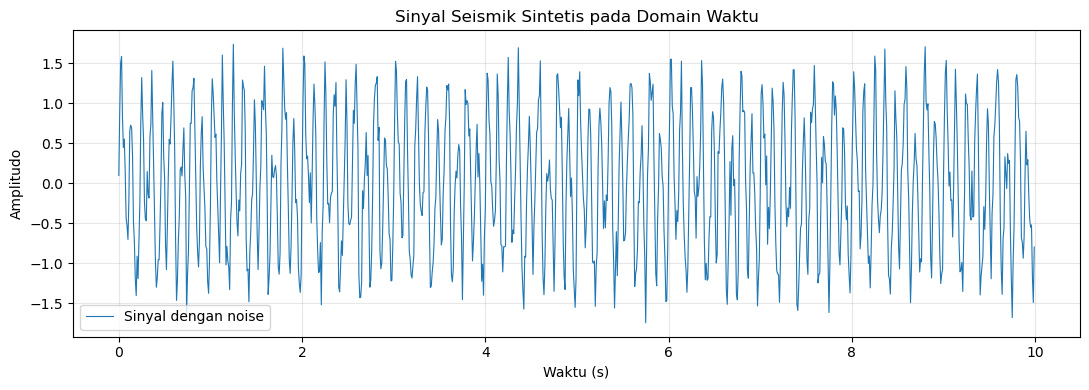

In [3]:
plt.figure(figsize=(11, 4))
plt.plot(t, signal, linewidth=0.8, label="Sinyal dengan noise")
plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo")
plt.title("Sinyal Seismik Sintetis pada Domain Waktu")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 2.4 Menghitung FFT

FFT dihitung menggunakan seluruh sampel sinyal. Karena sinyal yang dianalisis berupa sinyal real, spektrum yang digunakan adalah spektrum satu sisi pada frekuensi positif.

Resolusi frekuensi ditentukan oleh durasi rekaman. Semakin panjang durasi sinyal dengan sampling yang sama, semakin kecil interval frekuensi yang dapat dibedakan.

In [4]:
N = len(signal)

fft_values = np.fft.rfft(signal)
freq = np.fft.rfftfreq(N, d=1/fs)

amplitude = (2.0 / N) * np.abs(fft_values)
amplitude[0] /= 2.0

df = freq[1] - freq[0]

print(f"Resolusi frekuensi = {df:.3f} Hz")

Resolusi frekuensi = 0.100 Hz


## 2.5 Spektrum Amplitudo

Spektrum amplitudo digunakan untuk melihat distribusi energi/amplitudo sinyal terhadap frekuensi. Puncak spektrum menunjukkan komponen frekuensi yang paling kuat.

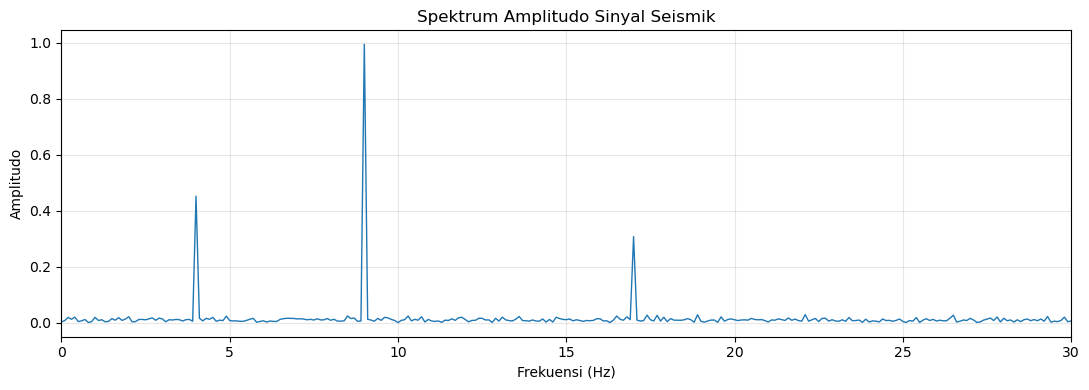

In [5]:
plt.figure(figsize=(11, 4))
plt.plot(freq, amplitude, linewidth=1.0)
plt.xlim(0, 30)
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitudo")
plt.title("Spektrum Amplitudo Sinyal Seismik")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2.6 Menentukan Frekuensi Dominan

Frekuensi dominan ditentukan sebagai frekuensi dengan amplitudo terbesar pada spektrum positif.

Nilai hasil FFT kemudian dibandingkan dengan frekuensi teoritis yang digunakan ketika sinyal dibuat. Perbandingan ini menjadi bentuk validasi sederhana terhadap proses analisis.

In [6]:
dominant_index = np.argmax(amplitude[1:]) + 1
dominant_frequency = freq[dominant_index]
dominant_amplitude = amplitude[dominant_index]

theoretical_dominant = frequencies[np.argmax(amplitudes)]
difference = abs(dominant_frequency - theoretical_dominant)

print(f"Frekuensi dominan hasil FFT : {dominant_frequency:.3f} Hz")
print(f"Frekuensi dominan teoritis  : {theoretical_dominant:.3f} Hz")
print(f"Selisih                      : {difference:.3f} Hz")

Frekuensi dominan hasil FFT : 9.000 Hz
Frekuensi dominan teoritis  : 9.000 Hz
Selisih                      : 0.000 Hz


## 2.7 Analisis Bandwidth

Bandwidth digunakan untuk menggambarkan rentang frekuensi yang masih mempunyai amplitudo cukup besar terhadap amplitudo maksimum.

Pada analisis ini digunakan ambang 50% dari amplitudo maksimum. Frekuensi di bawah dan di atas frekuensi dominan yang masih memenuhi ambang tersebut digunakan untuk memperkirakan batas bandwidth.

In [7]:
threshold = 0.50 * dominant_amplitude
mask = amplitude >= threshold

freq_above_threshold = freq[mask]

if len(freq_above_threshold) > 0:
    f_low = freq_above_threshold.min()
    f_high = freq_above_threshold.max()
    bandwidth = f_high - f_low
else:
    f_low = np.nan
    f_high = np.nan
    bandwidth = np.nan

print(f"Ambang 50% amplitudo maksimum : {threshold:.4f}")
print(f"Batas bawah                   : {f_low:.3f} Hz")
print(f"Batas atas                    : {f_high:.3f} Hz")
print(f"Bandwidth                     : {bandwidth:.3f} Hz")

Ambang 50% amplitudo maksimum : 0.4972
Batas bawah                   : 9.000 Hz
Batas atas                    : 9.000 Hz
Bandwidth                     : 0.000 Hz


## 2.8 Validasi Frekuensi Dominan

Hasil analisis dibandingkan dengan nilai teoritis. Karena sinyal memiliki resolusi frekuensi tertentu, nilai hasil FFT dapat memiliki selisih kecil dari frekuensi teoritis.

Validasi ini tidak dimaksudkan sebagai pembuktian terhadap data lapangan, tetapi sebagai pemeriksaan apakah proses pembentukan sinyal dan transformasi Fourier menghasilkan frekuensi yang sesuai.

In [8]:
validation = pd.DataFrame({
    "Parameter": [
        "Frekuensi dominan teoritis",
        "Frekuensi dominan hasil FFT",
        "Selisih"
    ],
    "Nilai (Hz)": [
        theoretical_dominant,
        dominant_frequency,
        difference
    ]
})

validation

,Parameter,Nilai (Hz)
0,Frekuensi dominan teoritis,9.0
1,Frekuensi dominan hasil FFT,9.0
2,Selisih,0.0


## 2.9 Pengaruh Noise terhadap Spektrum

Noise dapat menambahkan amplitudo pada berbagai frekuensi. Untuk melihat pengaruhnya, sinyal bersih dibandingkan dengan sinyal yang telah diberi noise.

Secara umum, semakin besar noise maka spektrum akan semakin menyebar. Namun, komponen dominan tetap dapat dikenali selama amplitudonya cukup besar dibandingkan gangguan.

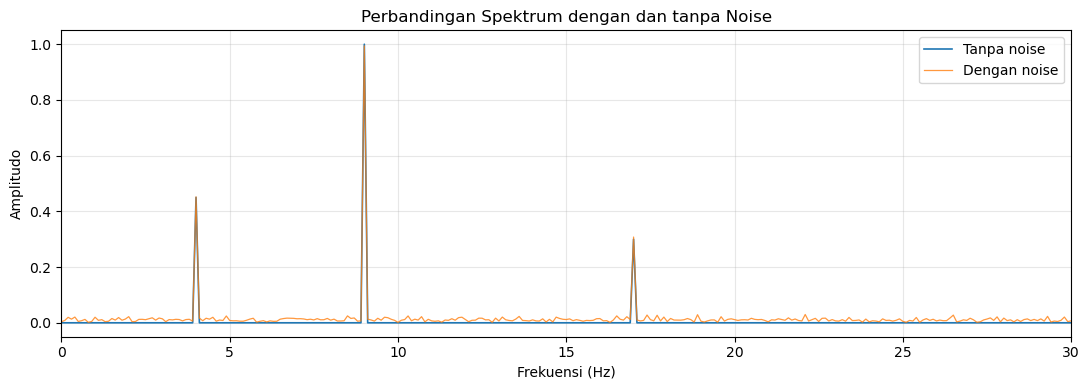

In [9]:
fft_clean = np.fft.rfft(signal_clean)
amp_clean = (2.0 / N) * np.abs(fft_clean)
amp_clean[0] /= 2.0

plt.figure(figsize=(11, 4))
plt.plot(freq, amp_clean, label="Tanpa noise", linewidth=1.2)
plt.plot(freq, amplitude, label="Dengan noise", linewidth=0.9, alpha=0.8)
plt.xlim(0, 30)
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitudo")
plt.title("Perbandingan Spektrum dengan dan tanpa Noise")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 2.10 Interpretasi Analisis Spektral

Hasil FFT menunjukkan adanya beberapa puncak yang berkaitan dengan komponen frekuensi pembentuk sinyal. Komponen dengan amplitudo terbesar menjadi frekuensi dominan.

Dalam konteks data seismik, informasi frekuensi dapat digunakan untuk memahami karakteristik sumber, bandwidth sinyal, kualitas rekaman, serta membantu menentukan tahapan pengolahan berikutnya.

Keberadaan noise menyebabkan spektrum tidak sepenuhnya bersih. Oleh karena itu, pada data nyata diperlukan proses tambahan seperti filtering atau analisis time-frequency apabila karakter sinyal berubah terhadap waktu.

# 3. Pemodelan Resistivitas Semu 1D

## 3.1 Dasar Teori

Metode resistivitas memanfaatkan respons listrik material bawah permukaan. Resistivitas merupakan ukuran kemampuan material dalam menghambat aliran arus listrik dan memiliki satuan ohm meter ($\Omega m$).

Hubungan sederhana antara resistansi dan resistivitas dapat dituliskan:

$$
R=\rho\frac{L}{A}
$$

Dalam survei geolistrik, arus listrik dialirkan ke dalam tanah melalui elektroda arus dan beda potensial diukur pada elektroda potensial. Nilai resistivitas semu kemudian dipengaruhi oleh resistivitas material bawah permukaan dan konfigurasi elektroda.

Pada notebook ini digunakan model dua lapisan untuk memperlihatkan hubungan antara parameter bawah permukaan dan respons resistivitas semu.

## 3.2 Parameter Model Bawah Permukaan

Model awal terdiri dari dua lapisan dengan parameter:

- Resistivitas lapisan 1 = 35 $\Omega m$
- Resistivitas lapisan 2 = 220 $\Omega m$
- Ketebalan lapisan 1 = 12 m

Nilai tersebut digunakan sebagai parameter acuan untuk menghasilkan data sintetis. Parameter hasil inversi nantinya dibandingkan dengan nilai acuan tersebut.

In [10]:
rho1_true = 35.0
rho2_true = 220.0
h1_true = 12.0

ab2 = np.logspace(0, 2.2, 35)

print(f"rho1 = {rho1_true:.1f} ohm.m")
print(f"rho2 = {rho2_true:.1f} ohm.m")
print(f"h1   = {h1_true:.1f} m")

rho1 = 35.0 ohm.m
rho2 = 220.0 ohm.m
h1   = 12.0 m


## 3.3 Fungsi Forward Model

Forward modeling digunakan untuk menghitung respons resistivitas semu berdasarkan parameter model.

Untuk kepentingan pembelajaran, digunakan fungsi transisi sederhana yang menghasilkan perubahan bertahap dari resistivitas lapisan pertama menuju resistivitas lapisan kedua terhadap bertambahnya jarak elektroda.

Pendekatan ini digunakan untuk menunjukkan prinsip dasar hubungan model dan data. Model ini bukan formulasi VES dua-lapisan eksak untuk interpretasi data lapangan.

In [11]:
def forward_resistivity(params, ab2_values):
    rho1, rho2, h1 = params
    transition = 1.0 - np.exp(-ab2_values / (3.0 * h1))
    rho_app = rho1 + (rho2 - rho1) * transition
    return rho_app

rho_app_clean = forward_resistivity(
    [rho1_true, rho2_true, h1_true],
    ab2
)

rho_app_clean[:5]

array([40.06817173, 40.86938987, 41.79486103, 42.86302678, 44.09478086])

## 3.4 Membentuk Data Sintetis

Data sintetis dibuat dari respons model kemudian diberikan noise relatif sebesar 5%. Noise digunakan untuk menggambarkan bahwa data pengukuran tidak selalu identik dengan respons teoritis.

In [12]:
relative_noise = 0.05
noise_res = np.random.normal(0, relative_noise, len(rho_app_clean))

rho_app_obs = rho_app_clean * (1.0 + noise_res)

data_res = pd.DataFrame({
    "AB/2 (m)": ab2,
    "Resistivitas Semu (ohm.m)": rho_app_obs
})

data_res.head()

,AB/2 (m),Resistivitas Semu (ohm.m)
0,1.000000,42.871652
1,1.160662,42.758851
2,1.347137,41.919473
3,1.563571,41.476543
4,1.814778,45.634181


## 3.5 Visualisasi Data Resistivitas Semu

Kurva resistivitas semu ditampilkan menggunakan skala logaritmik pada sumbu jarak elektroda. Skala ini membantu memperlihatkan perubahan data pada rentang jarak yang cukup lebar.

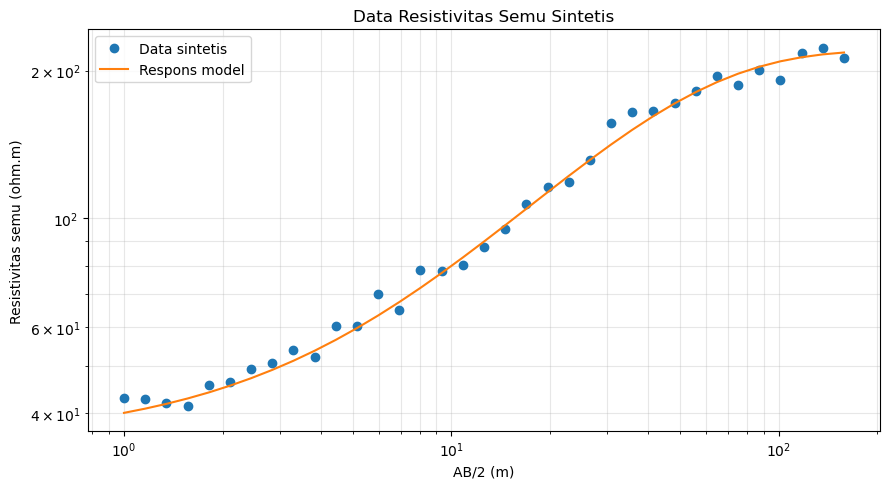

In [13]:
plt.figure(figsize=(9, 5))
plt.loglog(ab2, rho_app_obs, "o", label="Data sintetis")
plt.loglog(ab2, rho_app_clean, "-", label="Respons model")
plt.xlabel("AB/2 (m)")
plt.ylabel("Resistivitas semu (ohm.m)")
plt.title("Data Resistivitas Semu Sintetis")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3.6 Inversi Parameter

Inversi dilakukan dengan mencari parameter $\rho_1$, $\rho_2$, dan $h_1$ yang menghasilkan respons model paling dekat dengan data sintetis.

Karena parameter memiliki skala yang berbeda, optimasi dilakukan terhadap logaritma parameter. Residual dihitung dalam ruang logaritmik agar perbedaan relatif lebih terkontrol.

In [14]:
def residual_log_model(log_params, ab2_values, observed):
    params = np.exp(log_params)
    predicted = forward_resistivity(params, ab2_values)
    return np.log(predicted) - np.log(observed)

initial_params = np.array([50.0, 180.0, 10.0])

lower_bounds = np.array([5.0, 20.0, 1.0])
upper_bounds = np.array([500.0, 1000.0, 100.0])

result = least_squares(
    residual_log_model,
    x0=np.log(initial_params),
    bounds=(np.log(lower_bounds), np.log(upper_bounds)),
    args=(ab2, rho_app_obs)
)

estimated_params = np.exp(result.x)
rho1_est, rho2_est, h1_est = estimated_params

print(f"rho1 hasil inversi = {rho1_est:.3f} ohm.m")
print(f"rho2 hasil inversi = {rho2_est:.3f} ohm.m")
print(f"h1 hasil inversi   = {h1_est:.3f} m")
print(f"Status optimasi     = {result.message}")

rho1 hasil inversi = 35.968 ohm.m
rho2 hasil inversi = 217.040 ohm.m
h1 hasil inversi   = 11.465 m
Status optimasi     = `ftol` termination condition is satisfied.


## 3.7 Membandingkan Parameter Model

Hasil inversi dibandingkan dengan parameter acuan yang digunakan saat menghasilkan data. Perbandingan ini digunakan untuk melihat seberapa baik proses inversi dapat mengembalikan parameter model.

In [15]:
comparison = pd.DataFrame({
    "Parameter": ["rho1", "rho2", "h1"],
    "Nilai acuan": [rho1_true, rho2_true, h1_true],
    "Hasil inversi": [rho1_est, rho2_est, h1_est]
})

comparison["Selisih absolut"] = abs(
    comparison["Nilai acuan"] - comparison["Hasil inversi"]
)

comparison["Persentase selisih (%)"] = (
    comparison["Selisih absolut"] /
    comparison["Nilai acuan"] * 100
)

comparison

,Parameter,Nilai acuan,Hasil inversi,Selisih absolut,Persentase selisih (%)
0,rho1,35.0,35.967762,0.967762,2.765034
1,rho2,220.0,217.040222,2.959778,1.345354
2,h1,12.0,11.465353,0.534647,4.455389


## 3.8 Kurva Model Hasil Inversi

Kurva hasil inversi dibandingkan dengan data sintetis. Apabila kurva model mengikuti pola data, berarti parameter yang diperoleh memberikan respons yang cukup sesuai terhadap data yang digunakan.

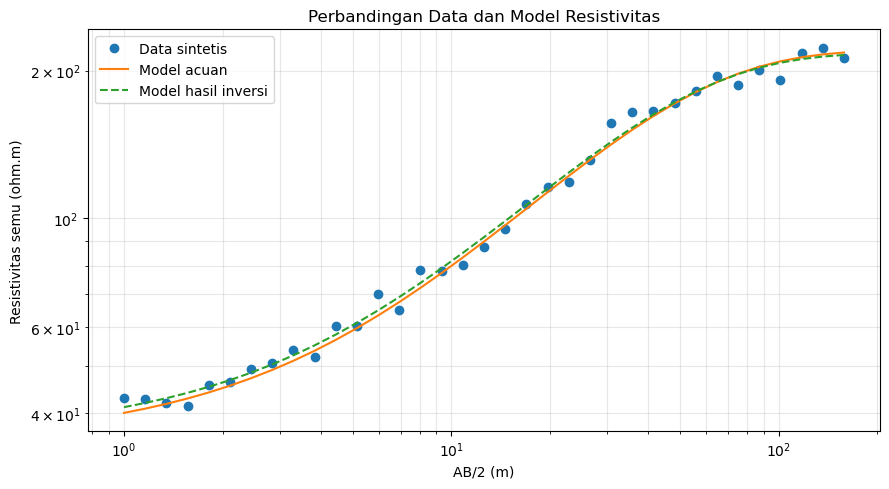

In [16]:
rho_app_inverted = forward_resistivity(estimated_params, ab2)

plt.figure(figsize=(9, 5))
plt.loglog(ab2, rho_app_obs, "o", label="Data sintetis")
plt.loglog(ab2, rho_app_clean, "-", label="Model acuan")
plt.loglog(ab2, rho_app_inverted, "--", label="Model hasil inversi")
plt.xlabel("AB/2 (m)")
plt.ylabel("Resistivitas semu (ohm.m)")
plt.title("Perbandingan Data dan Model Resistivitas")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3.9 Evaluasi Misfit

Misfit digunakan untuk mengukur perbedaan antara data dan respons model. Salah satu ukuran yang digunakan adalah root mean square error (RMSE) pada ruang logaritmik.

Nilai RMSE yang lebih kecil menunjukkan bahwa respons model semakin dekat dengan data yang dianalisis.

In [17]:
log_residual = np.log(rho_app_inverted) - np.log(rho_app_obs)
rmse_log = np.sqrt(np.mean(log_residual**2))

print(f"RMSE log = {rmse_log:.6f}")

RMSE log = 0.041182


## 3.10 Pengaruh Noise terhadap Inversi

Noise merupakan salah satu sumber ketidakpastian dalam inversi. Untuk melihat pengaruhnya, data dibuat dengan beberapa tingkat noise kemudian dilakukan inversi pada masing-masing kondisi.

Perubahan hasil parameter menunjukkan bahwa kualitas data dapat memengaruhi kestabilan model yang diperoleh.

In [18]:
noise_levels = [0.00, 0.02, 0.05, 0.10]
sensitivity_rows = []

for level in noise_levels:
    local_noise = np.random.normal(0, level, len(rho_app_clean))
    observed = rho_app_clean * (1.0 + local_noise)

    local_result = least_squares(
        residual_log_model,
        x0=np.log(initial_params),
        bounds=(np.log(lower_bounds), np.log(upper_bounds)),
        args=(ab2, observed)
    )

    local_params = np.exp(local_result.x)

    sensitivity_rows.append({
        "Noise (%)": level * 100,
        "rho1 (ohm.m)": local_params[0],
        "rho2 (ohm.m)": local_params[1],
        "h1 (m)": local_params[2]
    })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity

,Noise (%),rho1 (ohm.m),rho2 (ohm.m),h1 (m)
0,0.0,35.000000,220.000000,12.000000
1,2.0,34.919943,220.229638,11.908158
2,5.0,35.125995,222.921823,11.768528
3,10.0,33.561679,228.909971,12.431445


## 3.11 Interpretasi Pemodelan Resistivitas

Model menunjukkan adanya perbedaan resistivitas antara lapisan pertama dan lapisan kedua. Ketika jarak elektroda meningkat, respons resistivitas semu secara bertahap dipengaruhi oleh lapisan yang lebih dalam.

Hasil inversi digunakan untuk memperkirakan parameter resistivitas dan ketebalan lapisan. Perbedaan antara parameter acuan dan hasil inversi dapat dipengaruhi oleh noise serta karakteristik fungsi forward yang digunakan.

Dalam kondisi data lapangan, interpretasi resistivitas tidak cukup dilakukan hanya berdasarkan satu kurva. Informasi geologi, kualitas data, konfigurasi elektroda, dan ketidakpastian inversi perlu dipertimbangkan bersama.

# 4. Pembahasan

Kedua analisis menunjukkan dua bentuk pengolahan data geofisika yang berbeda.

Pada analisis spektral, informasi utama diperoleh dengan memindahkan sinyal dari domain waktu ke domain frekuensi. Hasilnya dapat digunakan untuk mengenali frekuensi dominan dan melihat pengaruh noise terhadap karakteristik sinyal.

Pada pemodelan resistivitas, informasi diperoleh melalui hubungan antara parameter model bawah permukaan dan respons geofisika. Forward modeling digunakan untuk menghasilkan respons model, sedangkan inversi digunakan untuk memperkirakan parameter berdasarkan data.

Keduanya menunjukkan pentingnya proses validasi. Hasil komputasi tidak cukup hanya ditampilkan, tetapi perlu dibandingkan dengan nilai acuan, dievaluasi terhadap noise, dan kemudian diinterpretasikan berdasarkan konsep geofisika.

# 5. Keterbatasan

Beberapa keterbatasan analisis dalam notebook ini adalah:

1. Data yang digunakan merupakan data sintetis.
2. Sinyal seismik dibuat dari kombinasi sinusoidal sehingga lebih sederhana daripada sinyal seismik lapangan.
3. Noise yang digunakan berupa noise acak dan belum mewakili seluruh jenis gangguan pada data nyata.
4. Model resistivitas hanya terdiri atas dua lapisan.
5. Fungsi forward resistivitas menggunakan pendekatan pedagogis, bukan penyelesaian VES dua-lapisan eksak.
6. Hasil inversi dipengaruhi oleh noise, parameter awal, batas parameter, dan bentuk fungsi forward.
7. Pada data lapangan, satu set data dapat memiliki lebih dari satu model yang dapat memberikan respons yang serupa.

Dengan demikian, hasil notebook ini digunakan untuk memahami konsep dan alur analisis, bukan sebagai pengganti pemrosesan data lapangan secara profesional.

# 6. Kesimpulan

Berdasarkan seluruh proses yang telah dilakukan, dapat disimpulkan bahwa:

1. FFT dapat digunakan untuk mengidentifikasi komponen frekuensi dalam sinyal seismik.
2. Frekuensi dominan hasil FFT dapat dibandingkan dengan frekuensi yang digunakan pada pembentukan sinyal sintetis.
3. Noise menambah komponen pada spektrum, tetapi frekuensi dominan masih dapat dikenali jika sinyal utama cukup kuat.
4. Forward modeling resistivitas dapat digunakan untuk menghasilkan respons data berdasarkan parameter model bawah permukaan.
5. Inversi dapat digunakan untuk memperkirakan parameter model dari data resistivitas sintetis.
6. Tingkat noise memengaruhi hasil estimasi parameter dan dapat meningkatkan ketidakpastian inversi.
7. Pengolahan data geofisika perlu diikuti dengan validasi dan interpretasi agar hasil numerik memiliki makna geofisika.

# 7. Daftar Pustaka

1. Gupta, P. K., Niwas, S., & Gaur, V. K. (1997). Straightforward inversion of vertical electrical sounding data. *Geophysics, 62*(3), 775–785.  
   DOI: https://doi.org/10.1190/1.1444187

2. Porsani, M. J., Niwas, S., & Ferreira, F. J. F. (2001). Robust inversion of vertical electrical sounding data using a multiple reweighted least-squares method. *Geophysical Prospecting, 49*(2), 255–264.  
   DOI: https://doi.org/10.1046/j.1365-2478.2001.00249.x

3. Jha, M. K., Kumar, S., & Chowdhury, A. (2008). Vertical electrical sounding survey and resistivity inversion using genetic algorithm optimization technique. *Journal of Hydrology, 359*(1–2), 71–87.  
   DOI: https://doi.org/10.1016/j.jhydrol.2008.06.018

4. Irawan, D., Grandis, H., & Sumintadireja, P. (2015). Quasi-2D resistivity model from inversion of vertical electrical sounding (VES) data using guided random search algorithm. *Journal of Mathematical and Fundamental Sciences, 47*(3), 269–280.  
   DOI: https://doi.org/10.5614/j.math.fund.sci.2015.47.3.5

5. Aleardi, M., Vinciguerra, V., & Hojat, A. (2021). A geostatistical Markov chain Monte Carlo inversion algorithm for electrical resistivity tomography. *Near Surface Geophysics, 19*, 7–26.  
   DOI: https://doi.org/10.1002/nsg.12133